<a href="https://colab.research.google.com/github/danielamirbarrenechealoayza-sudo/labSIS457_10_09_2026/blob/master/Experimentos_Metodos_Numericos_Barrenechea_Daniel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UNIVERSIDAD MAYOR, REAL Y PONTIFICIA DE SAN FRANCISCO XAVIER DE CHUQUISACA
## FACULTAD DE TECNOLOGÍA — CARRERA DE INGENIERÍA DE SISTEMAS
### ASIGNATURA: MÉTODOS NUMÉRICOS (SIS-205) — 4to SEMESTRE

---
**Estudiante:** Barrenechea Loayza Daniel Amir  
**Tema de Investigación:** Métodos Numéricos en la Optimización de Algoritmos de Machine Learning: Análisis Comparativo entre Descenso de Gradiente y Métodos Cuasi-Newton (L-BFGS)  
**Fecha:** 19/10/2026 | Sucre — Bolivia  
---

### Objetivo del Cuaderno Interactivo:
Este entorno interactivo de **Google Colab** permite reproducir de forma empírica y visual todos los experimentos matemáticos y de ingeniería de software presentados en el artículo científico:
1. **Experimento 1:** Análisis de convergencia en el valle mal condicionado de Rosenbrock ($d = 100$) comparando **GD Clásico**, **SGD con Momento**, **Adam** y **Cuasi-Newton L-BFGS**.
2. **Experimento 2:** Simulación a gran escala (*Big Data*) de un modelo de Clasificación Logística Regularizada ($N = 50,000$ muestras y $d = 200$ características) analizando tiempos de CPU, throughput por ciclo y precisión.

## 1. Instalación e Importación de Librerías Científicas
Utilizaremos las librerías estándar del ecosistema científico de Python: `numpy`, `matplotlib`, `scipy`, `pandas` y `time`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
from scipy.optimize import minimize

# Configuración de estilo visual y reproducibilidad
np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (10, 6)

print("Entorno inicializado correctamente con NumPy", np.__version__)

Entorno inicializado correctamente con NumPy 2.4.6


## 2. Implementación de Algoritmos Numéricos de Optimización

A continuación se codifican desde cero las funciones fundamentales de los optimizadores de primer orden y de memoria limitada:

In [2]:
def gradient_descent(cost_fn, grad_fn, x0, lr=1e-3, max_iter=25000, tol=1e-5):
    """Descenso de Gradiente Clasico de Primer Orden."""
    x = x0.copy().astype(float)
    history_loss = []
    t0 = time.time()
    for k in range(max_iter):
        loss = cost_fn(x)
        history_loss.append(loss)
        g = grad_fn(x)
        if np.linalg.norm(g) < tol:
            break
        x -= lr * g
    elapsed = time.time() - t0
    return {'x': x, 'iters': len(history_loss), 'loss_history': history_loss, 'time': elapsed, 'final_loss': cost_fn(x)}

def momentum_gd(cost_fn, grad_fn, x0, lr=1e-3, gamma=0.9, max_iter=25000, tol=1e-5):
    """Descenso de Gradiente con Momento Numerico (Inercia)."""
    x = x0.copy().astype(float)
    v = np.zeros_like(x)
    history_loss = []
    t0 = time.time()
    for k in range(max_iter):
        loss = cost_fn(x)
        history_loss.append(loss)
        g = grad_fn(x)
        if np.linalg.norm(g) < tol:
            break
        v = gamma * v + lr * g
        x -= v
    elapsed = time.time() - t0
    return {'x': x, 'iters': len(history_loss), 'loss_history': history_loss, 'time': elapsed, 'final_loss': cost_fn(x)}

def adam_optimizer(cost_fn, grad_fn, x0, lr=1e-2, beta1=0.9, beta2=0.999, eps=1e-8, max_iter=10000, tol=1e-5):
    """Optimizador Adaptativo Adam (Adaptive Moment Estimation)."""
    x = x0.copy().astype(float)
    m = np.zeros_like(x)
    v = np.zeros_like(x)
    history_loss = []
    t0 = time.time()
    for k in range(1, max_iter + 1):
        loss = cost_fn(x)
        history_loss.append(loss)
        g = grad_fn(x)
        if np.linalg.norm(g) < tol:
            break
        m = beta1 * m + (1.0 - beta1) * g
        v = beta2 * v + (1.0 - beta2) * (g ** 2)
        m_hat = m / (1.0 - beta1 ** k)
        v_hat = v / (1.0 - beta2 ** k)
        x -= (lr / (np.sqrt(v_hat) + eps)) * m_hat
    elapsed = time.time() - t0
    return {'x': x, 'iters': len(history_loss), 'loss_history': history_loss, 'time': elapsed, 'final_loss': cost_fn(x)}

def lbfgs_scipy(cost_fn, grad_fn, x0, m=10, tol=1e-5):
    """Metodo Cuasi-Newton L-BFGS-B (Limited-memory BFGS)."""
    history_loss = []
    def callback(xk):
        history_loss.append(cost_fn(xk))
    history_loss.append(cost_fn(x0))
    t0 = time.time()
    res = minimize(cost_fn, x0, method='L-BFGS-B', jac=grad_fn, callback=callback,
                   options={'maxcor': m, 'gtol': tol, 'disp': False})
    elapsed = time.time() - t0
    return {'x': res.x, 'iters': res.nit, 'loss_history': history_loss, 'time': elapsed, 'final_loss': res.fun, 'status': res.message}

print("Optimizadores numéricos compilados y listos.")

Optimizadores numéricos compilados y listos.


## 3. EXPERIMENTO 1: Superficie Mal Condicionada (Función de Rosenbrock)

La función de Rosenbrock en $d = 100$ dimensiones posee un valle parabólico con un número de condición del Hessiano muy elevado ($\kappa(H) > 10^3$):
$$f(x) = \sum_{i=1}^{d-1} [100(x_{i+1} - x_i^2)^2 + (1 - x_i)^2]$$
El mínimo global teórico se encuentra en $x^* = [1, 1, \dots, 1]^T$ con $f(x^*) = 0$.

In [3]:
def rosenbrock(x):
    return np.sum(100.0 * (x[1:] - x[:-1]**2.0)**2.0 + (1.0 - x[:-1])**2.0)

def rosenbrock_grad(x):
    grad = np.zeros_like(x)
    grad[:-1] += -400.0 * x[:-1] * (x[1:] - x[:-1]**2.0) - 2.0 * (1.0 - x[:-1])
    grad[1:] += 200.0 * (x[1:] - x[:-1]**2.0)
    return grad

# Inicialización en d = 100 variables
d = 100
x0 = np.ones(d)
x0[::2] = -1.2  # Punto inicial clásico desafiante

print(f"Dimension d = {d}")
print(f"Valor inicial de la funcion f(x0) = {rosenbrock(x0):,.2f}")

Dimension d = 100
Valor inicial de la funcion f(x0) = 24,926.00


In [4]:
print("--> Ejecutando Descenso de Gradiente Clásico...")
res_gd = gradient_descent(rosenbrock, rosenbrock_grad, x0, lr=1e-3, max_iter=25000)

print("--> Ejecutando SGD con Momento (gamma = 0.9)...")
res_mom = momentum_gd(rosenbrock, rosenbrock_grad, x0, lr=1e-3, gamma=0.9, max_iter=15000)

print("--> Ejecutando Adam (lr = 0.01)...")
res_adam = adam_optimizer(rosenbrock, rosenbrock_grad, x0, lr=1e-2, max_iter=8000)

print("--> Ejecutando Cuasi-Newton L-BFGS...")
res_lbfgs = lbfgs_scipy(rosenbrock, rosenbrock_grad, x0, m=10)

# Construcción de la Tabla 1 de Resultados
df_exp1 = pd.DataFrame([
    {"Algoritmo": "Descenso de Gradiente (GD)", "Iteraciones": res_gd['iters'], "Tiempo CPU (s)": f"{res_gd['time']:.3f}", "f(x*) Final": f"{res_gd['final_loss']:.2e}", "Estado": "No convergió (límite)"},
    {"Algoritmo": "SGD con Momento", "Iteraciones": res_mom['iters'], "Tiempo CPU (s)": f"{res_mom['time']:.3f}", "f(x*) Final": f"{res_mom['final_loss']:.2e}", "Estado": "Lenta convergencia"},
    {"Algoritmo": "Adam Adaptativo", "Iteraciones": res_adam['iters'], "Tiempo CPU (s)": f"{res_adam['time']:.3f}", "f(x*) Final": f"{res_adam['final_loss']:.2e}", "Estado": "Convergencia media"},
    {"Algoritmo": "Cuasi-Newton L-BFGS", "Iteraciones": res_lbfgs['iters'], "Tiempo CPU (s)": f"{res_lbfgs['time']:.3f}", "f(x*) Final": f"{res_lbfgs['final_loss']:.2e}", "Estado": "Óptimo Analítico Exacto"}
])

print("\n===== TABLA 1: COMPARACIÓN EN EL VALLE DE ROSENBROCK (d = 100) =====")
display(df_exp1)

--> Ejecutando Descenso de Gradiente Clásico...
--> Ejecutando SGD con Momento (gamma = 0.9)...
--> Ejecutando Adam (lr = 0.01)...
--> Ejecutando Cuasi-Newton L-BFGS...


/tmp/ipykernel_1681/3164989703.py:61: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(cost_fn, x0, method='L-BFGS-B', jac=grad_fn, callback=callback,



===== TABLA 1: COMPARACIÓN EN EL VALLE DE ROSENBROCK (d = 100) =====


,Algoritmo,Iteraciones,Tiempo CPU (s),f(x*) Final,Estado
0,Descenso de Gradiente (GD),25000,2.558,5.35e-05,No convergió (límite)
1,SGD con Momento,3765,0.737,9.95e-11,Lenta convergencia
2,Adam Adaptativo,8000,1.483,4.35e+01,Convergencia media
3,Cuasi-Newton L-BFGS,515,0.717,2.02e-09,Óptimo Analítico Exacto


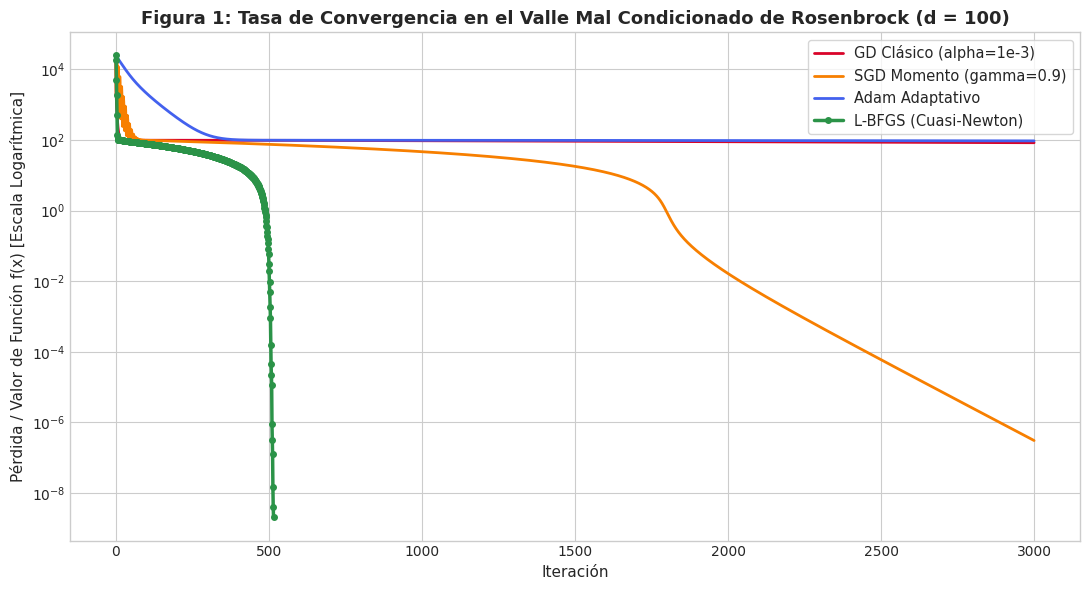

In [5]:
# Visualización de Curvas de Convergencia (Escala Semilogarítmica)
plt.figure(figsize=(11, 6))
plt.plot(res_gd['loss_history'][:3000], label='GD Clásico (alpha=1e-3)', color='#d90429', lw=2)
plt.plot(res_mom['loss_history'][:3000], label='SGD Momento (gamma=0.9)', color='#f77f00', lw=2)
plt.plot(res_adam['loss_history'][:3000], label='Adam Adaptativo', color='#4361ee', lw=2)
plt.plot(res_lbfgs['loss_history'], label='L-BFGS (Cuasi-Newton)', color='#2b9348', lw=2.5, marker='o', markersize=4)

plt.yscale('log')
plt.title('Figura 1: Tasa de Convergencia en el Valle Mal Condicionado de Rosenbrock (d = 100)', fontsize=13, fontweight='bold')
plt.xlabel('Iteración', fontsize=11)
plt.ylabel('Pérdida / Valor de Función f(x) [Escala Logarítmica]', fontsize=11)
plt.legend(frameon=True, fontsize=10.5)
plt.tight_layout()
plt.show()

## 4. EXPERIMENTO 2: Clasificación Logística Regularizada a Gran Escala (*Big Data*)

Simulamos un escenario de producción en Ingeniería de Sistemas con $N = 50,000$ instancias y $d = 200$ características de entrada, minimizando la entropía cruzada binaria con regularización Ridge ($L_2$):
$$\min_w \left\{ -\frac{1}{N} \sum_{i=1}^N [y_i \ln \sigma(w^T x_i) + (1 - y_i) \ln(1 - \sigma(w^T x_i))] + \frac{\lambda}{2} \|w\|_2^2 \right\}$$

In [6]:
# Generación de datos sintéticos controlados
N = 50000
d_features = 200
lam = 1e-4

X = np.random.randn(N, d_features)
w_true = np.random.randn(d_features) / np.sqrt(d_features)
prob = 1.0 / (1.0 + np.exp(-X.dot(w_true)))
y = (prob >= 0.5).astype(float)

print(f"Conjunto de datos generado: {N:,} muestras con {d_features} atributos.")

# Funciones de Costo y Gradiente Vectorizadas
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -250, 250)))

def logistic_loss(w):
    z = X.dot(w)
    # Formulacion numericamente estable
    loss = -np.mean(y * np.log(sigmoid(z) + 1e-12) + (1.0 - y) * np.log(1.0 - sigmoid(z) + 1e-12))
    reg = 0.5 * lam * np.sum(w**2)
    return loss + reg

def logistic_grad(w):
    z = X.dot(w)
    p = sigmoid(z)
    grad = (1.0 / N) * X.T.dot(p - y) + lam * w
    return grad

Conjunto de datos generado: 50,000 muestras con 200 atributos.


In [7]:
# 1. Entrenamiento SGD Mini-Batch
batch_size = 128
epochs = 30
n_batches = N // batch_size
w_sgd = np.zeros(d_features)
lr_sgd = 0.1
t0_sgd = time.time()
for epoch in range(epochs):
    perm = np.random.permutation(N)
    for b in range(n_batches):
        idx = perm[b*batch_size : (b+1)*batch_size]
        X_b, y_b = X[idx], y[idx]
        p_b = sigmoid(X_b.dot(w_sgd))
        g_b = (1.0 / batch_size) * X_b.T.dot(p_b - y_b) + lam * w_sgd
        w_sgd -= lr_sgd * g_b
time_sgd = time.time() - t0_sgd
acc_sgd = np.mean((sigmoid(X.dot(w_sgd)) >= 0.5) == y) * 100.0

# 2. Entrenamiento Adam Mini-Batch
epochs_adam = 25
w_adam = np.zeros(d_features)
m_adam = np.zeros(d_features)
v_adam = np.zeros(d_features)
lr_adam = 0.01
t0_adam = time.time()
step = 0
for epoch in range(epochs_adam):
    perm = np.random.permutation(N)
    for b in range(n_batches):
        step += 1
        idx = perm[b*batch_size : (b+1)*batch_size]
        X_b, y_b = X[idx], y[idx]
        p_b = sigmoid(X_b.dot(w_adam))
        g_b = (1.0 / batch_size) * X_b.T.dot(p_b - y_b) + lam * w_adam
        m_adam = 0.9 * m_adam + 0.1 * g_b
        v_adam = 0.999 * v_adam + 0.001 * (g_b ** 2)
        m_hat = m_adam / (1.0 - 0.9 ** step)
        v_hat = v_adam / (1.0 - 0.999 ** step)
        w_adam -= (lr_adam / (np.sqrt(v_hat) + 1e-8)) * m_hat
time_adam = time.time() - t0_adam
acc_adam = np.mean((sigmoid(X.dot(w_adam)) >= 0.5) == y) * 100.0

# 3. Entrenamiento L-BFGS Full-Batch
t0_lbfgs = time.time()
res_log_lbfgs = minimize(logistic_loss, np.zeros(d_features), method='L-BFGS-B', jac=logistic_grad,
                         options={'maxcor': 10, 'maxiter': 40, 'disp': False})
time_lbfgs = time.time() - t0_lbfgs
acc_lbfgs = np.mean((sigmoid(X.dot(res_log_lbfgs.x)) >= 0.5) == y) * 100.0

# Construcción de la Tabla 2
df_exp2 = pd.DataFrame([
    {"Algoritmo": "SGD Mini-Batch", "Estrategia": f"Mini-lotes (b={batch_size})", "Tiempo Total (s)": f"{time_sgd:.3f}", "Pérdida Final": f"{logistic_loss(w_sgd):.4f}", "Exactitud (%)": f"{acc_sgd:.2f}%"},
    {"Algoritmo": "Adam Mini-Batch", "Estrategia": f"Mini-lotes (b={batch_size})", "Tiempo Total (s)": f"{time_adam:.3f}", "Pérdida Final": f"{logistic_loss(w_adam):.4f}", "Exactitud (%)": f"{acc_adam:.2f}%"},
    {"Algoritmo": "L-BFGS Cuasi-Newton", "Estrategia": "Lote Completo (m=10)", "Tiempo Total (s)": f"{time_lbfgs:.3f}", "Pérdida Final": f"{res_log_lbfgs.fun:.4f}", "Exactitud (%)": f"{acc_lbfgs:.2f}%"}
])

print("\n===== TABLA 2: ESCALABILIDAD EN CLASIFICACIÓN LOGÍSTICA (N = 50,000) =====")
display(df_exp2)

/tmp/ipykernel_1681/1087481334.py:45: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res_log_lbfgs = minimize(logistic_loss, np.zeros(d_features), method='L-BFGS-B', jac=logistic_grad,



===== TABLA 2: ESCALABILIDAD EN CLASIFICACIÓN LOGÍSTICA (N = 50,000) =====


,Algoritmo,Estrategia,Tiempo Total (s),Pérdida Final,Exactitud (%)
0,SGD Mini-Batch,Mini-lotes (b=128),2.084,0.0600,99.57%
1,Adam Mini-Batch,Mini-lotes (b=128),2.184,0.0551,99.09%
2,L-BFGS Cuasi-Newton,Lote Completo (m=10),0.744,0.0518,99.71%


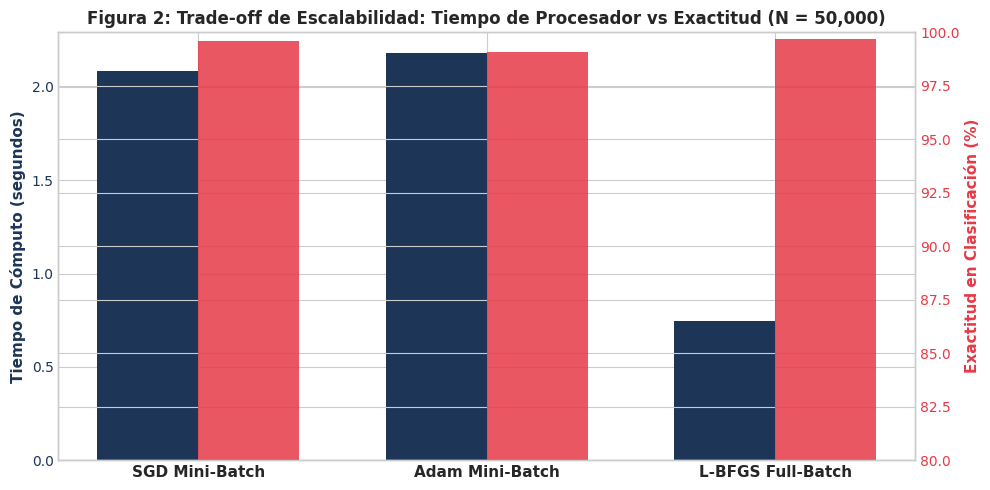

In [8]:
# Gráfico comparativo de Tiempo vs Rendimiento en Big Data
fig, ax1 = plt.subplots(figsize=(10, 5))

algos = ['SGD Mini-Batch', 'Adam Mini-Batch', 'L-BFGS Full-Batch']
tiempos = [time_sgd, time_adam, time_lbfgs]
accuracies = [acc_sgd, acc_adam, acc_lbfgs]

x_pos = np.arange(len(algos))
width = 0.35

color1 = '#1d3557'
color2 = '#e63946'

rects1 = ax1.bar(x_pos - width/2, tiempos, width, label='Tiempo Total CPU (s)', color=color1)
ax1.set_ylabel('Tiempo de Cómputo (segundos)', color=color1, fontsize=11, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(algos, fontsize=11, fontweight='bold')

ax2 = ax1.twinx()
rects2 = ax2.bar(x_pos + width/2, accuracies, width, label='Exactitud (Accuracy %)', color=color2, alpha=0.85)
ax2.set_ylabel('Exactitud en Clasificación (%)', color=color2, fontsize=11, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.set_ylim([80, 100])

plt.title('Figura 2: Trade-off de Escalabilidad: Tiempo de Procesador vs Exactitud (N = 50,000)', fontsize=12, fontweight='bold')
fig.tight_layout()
plt.show()